In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

## step1. load the datasettatype...etc
## 1. we can collect dataset from any websites,govt org,pvt orgs,ngos,kaggale dataset,data,gov....etc
## 2. using pandas library i had loaded the data and converted into dataframes 
## 3. i had verified no of rows and columns present in the dataset
## 4. i had verified information related to all columns like column and its datatype...etc

In [2]:
df = pd.read_excel('pima-data.xlsx')
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True
...,...,...,...,...,...,...,...,...,...,...,...
763,10,101,76,48,180,32.9,0.171,63,0,1.8912,False
764,2,122,70,27,0,36.8,0.340,27,0,1.0638,False
765,5,121,72,23,112,26.2,0.245,30,0,0.9062,False
766,1,126,60,0,0,30.1,0.349,47,1,0.0000,True


In [3]:
df.shape

(768, 11)

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 768 entries, 0 to 767
Data columns (total 11 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   num_preg       768 non-null    int64  
 1   glucose_conc   768 non-null    int64  
 2   diastolic_bp   768 non-null    int64  
 3   thickness      768 non-null    int64  
 4   insulin        768 non-null    int64  
 5   bmi            768 non-null    float64
 6   diab_pred      768 non-null    float64
 7   age            768 non-null    int64  
 8   diabetes_orig  768 non-null    int64  
 9   skin           768 non-null    float64
 10  diabetes       768 non-null    bool   
dtypes: bool(1), float64(3), int64(7)
memory usage: 60.9 KB


In [5]:
pd.set_option('display.max_rows',None)

In [6]:
df

,num_preg,glucose_conc,diastolic_bp,thickness,insulin,bmi,diab_pred,age,diabetes_orig,skin,diabetes
0,6,148,72,35,0,33.6,0.627,50,1,1.3790,True
1,1,85,66,29,0,26.6,0.351,31,0,1.1426,False
2,8,183,64,0,0,23.3,0.672,32,1,0.0000,True
3,1,89,66,23,94,28.1,0.167,21,0,0.9062,False
4,0,137,40,35,168,43.1,2.288,33,1,1.3790,True
5,5,116,74,0,0,25.6,0.201,30,0,0.0000,False
6,3,78,50,32,88,31.0,0.248,26,1,1.2608,True
7,10,115,0,0,0,35.3,0.134,29,0,0.0000,False
8,2,197,70,45,543,30.5,0.158,53,1,1.7730,True
9,8,125,96,0,0,0.0,0.232,54,1,0.0000,True


## step2. cleaning the dataset

## 1. identify the null values present in the dataset

In [7]:
df.isnull().sum()

num_preg         0
glucose_conc     0
diastolic_bp     0
thickness        0
insulin          0
bmi              0
diab_pred        0
age              0
diabetes_orig    0
skin             0
diabetes         0
dtype: int64

In [8]:
df.isnull().values.any()

np.False_

## 2. check the correlation between two columns

Figure(1200x1200)
Axes(0.125,0.11;0.775x0.77)


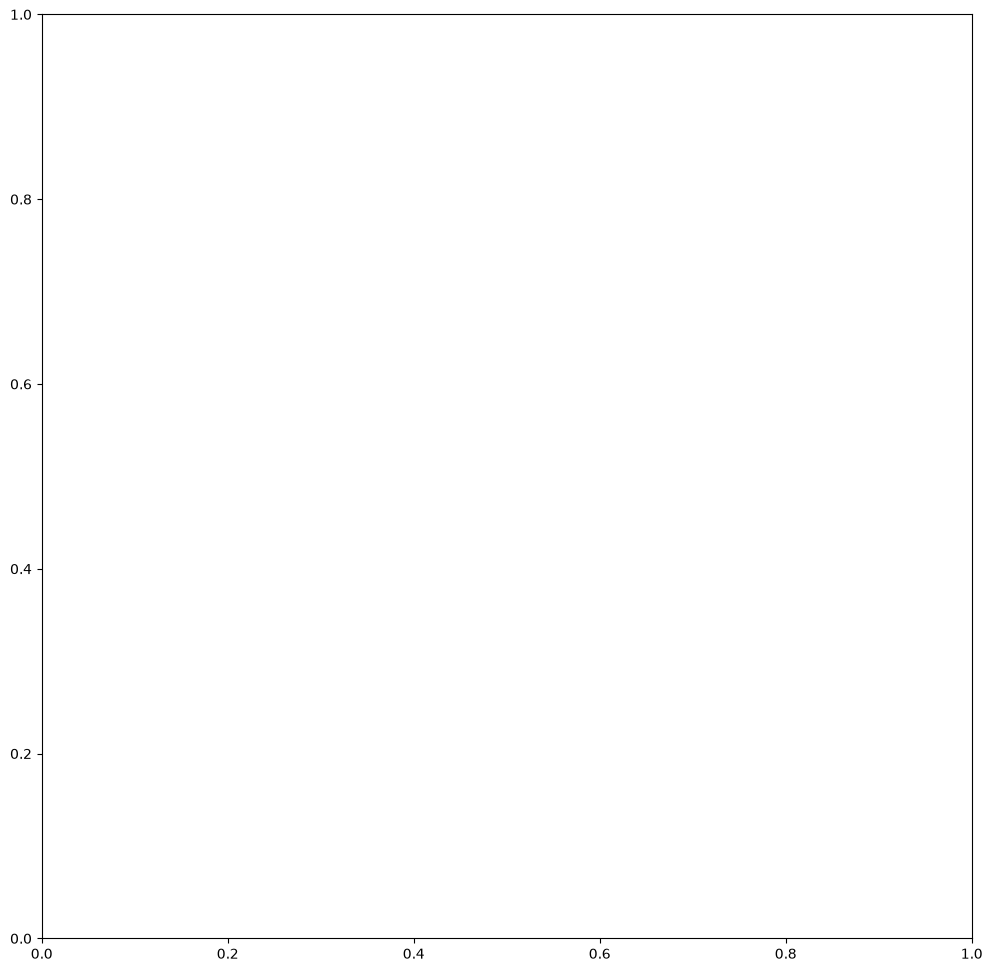

In [9]:
corr = df.corr()
fig,ax=plt.subplots(figsize=(12,12))
print(fig)
print(ax)

In [10]:
def check_corr():
    corr = df.corr()
    fig,ax=plt.subplots(figsize=(12,12))
    cmap='plasma'
    ax.matshow(corr,cmap=cmap)
    plt.xticks(range(len(df.columns)),corr.columns,rotation=45)
    plt.yticks(range(len(df.columns)),corr.columns)
    plt.show()

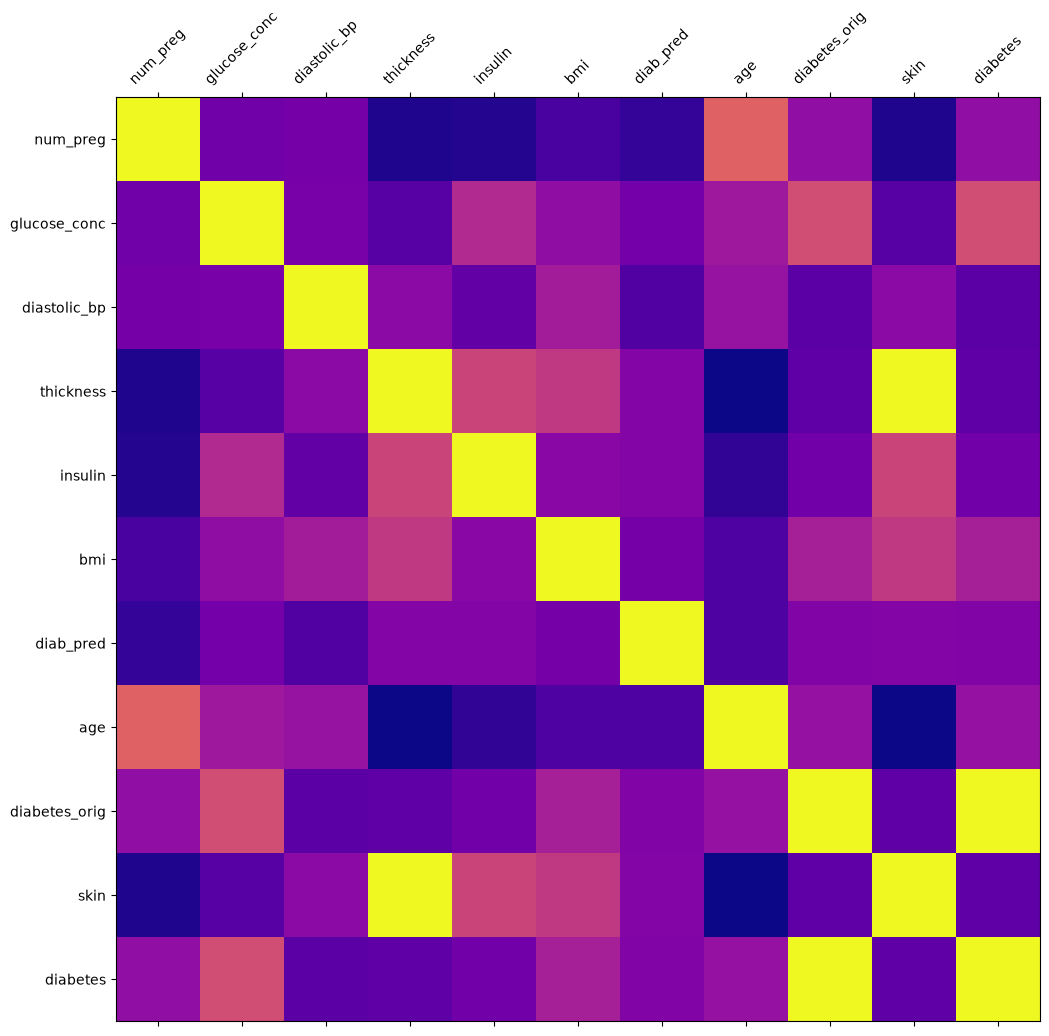

In [11]:
check_corr()

## thickness and skin are correleated to each other
## diabetes_org and diabetes are correleated to each other

## 3. drop the correleated columns

In [12]:
df.drop('thickness',axis=1,inplace=True)
df.drop('diabetes_orig',axis=1,inplace=True)

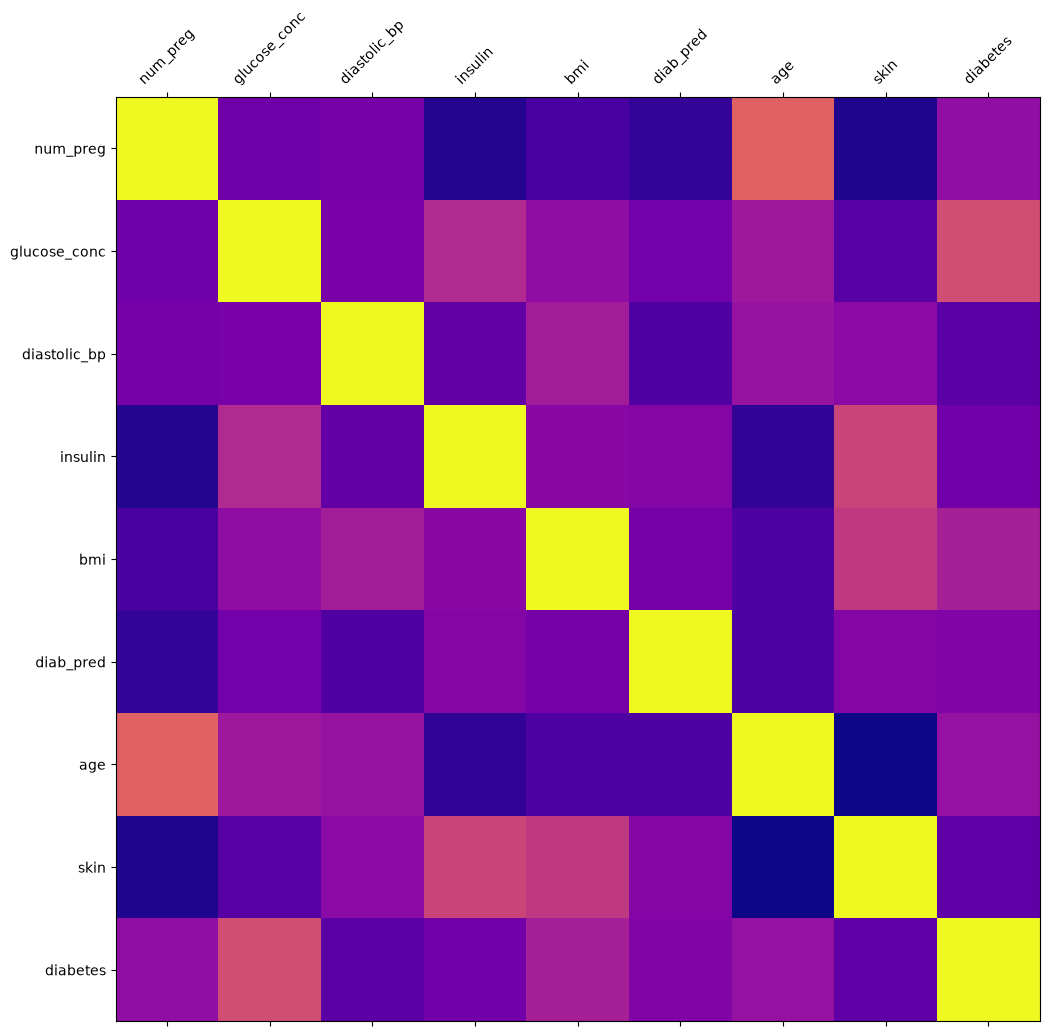

In [13]:
check_corr()

## 4. convert data into integer values

In [14]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,True
1,1,85,66,0,26.6,0.351,31,1.1426,False
2,8,183,64,0,23.3,0.672,32,0.0000,True
3,1,89,66,94,28.1,0.167,21,0.9062,False
4,0,137,40,168,43.1,2.288,33,1.3790,True


In [15]:
dict1 = {"diabetes":[True,False]}
dict2 = {"diabetes":[1,0]}

df.replace(dict1,dict2,inplace=True)

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1
5,5,116,74,0,25.6,0.201,30,0.0000,0
6,3,78,50,88,31.0,0.248,26,1.2608,1
7,10,115,0,0,35.3,0.134,29,0.0000,0
8,2,197,70,543,30.5,0.158,53,1.7730,1
9,8,125,96,0,0.0,0.232,54,0.0000,1


In [16]:
df.head()

,num_preg,glucose_conc,diastolic_bp,insulin,bmi,diab_pred,age,skin,diabetes
0,6,148,72,0,33.6,0.627,50,1.3790,1
1,1,85,66,0,26.6,0.351,31,1.1426,0
2,8,183,64,0,23.3,0.672,32,0.0000,1
3,1,89,66,94,28.1,0.167,21,0.9062,0
4,0,137,40,168,43.1,2.288,33,1.3790,1


## 5. check the dataset is balanced or not

In [17]:
num_true=len(df[df['diabetes'] == 1])
num_false=len(df[df['diabetes'] == 0])
print(num_true)
print(num_false)
true_percentage=((num_true)/(num_true+num_false))*100
print(true_percentage)
false_percentage=((num_true)/(num_true+num_false))*100
print(false_percentage)

268
500
34.89583333333333
34.89583333333333


## 3.train test split

In [18]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'diabetes'],
      dtype='str')

In [19]:
## pip install scikit-learn

In [27]:
from sklearn.model_selection import train_test_split

input_columns = [
    'num_preg',
    'glucose_conc',
    'diastolic_bp',
    'insulin',
    'bmi',
    'diab_pred',
    'age',
    'skin'
]

output_columns = ['diabetes']

x = df[input_columns].values
y = df[output_columns].values

split_test_size = 0.3

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=split_test_size,
    random_state=42
)

In [ ]:
#def m1(x,y):
#   s1 = x+y
#   s2 = x-y
#   return s1,s2
#sum1,sub1=m1(10,20)
#print(sum1)
#print(sub1)

In [28]:
print(x_train.shape)
print(y_train.shape)
print(x_test.shape)
print(x_test.shape)

(537, 8)
(537, 1)
(231, 8)
(231, 8)


In [29]:
print('{0:0.2f} in training set:'.format(len(x_train)/len(df.index)*100))
print('{0:0.2f} in testing set:'.format(len(x_test)/len(df.index)*100))

69.92 in training set:
30.08 in testing set:


In [30]:
print('training_true {0} ({1:0.2f}%) in training set:'.format(
    len(y_train[y_train[:] == 1]),(len(y_train[y_train[:] == 1])/len(y_train)*100)))

print('training_false {0} ({1:0.2f}%) in training set:'.format(
    len(y_train[y_train[:] ==0]),(len(y_train[y_train[:] == 0])/len(y_train)*100)))

print('training_true {0} ({1:0.2f}%) in testing set:'.format(
    len(y_train[y_train[:] == 1]),(len(y_train[y_train[:] == 1])/len(y_train)*100)))


print('training_false {0} ({1:0.2f}%) in testing set:'.format(
    len(y_train[y_train[:] == 0]),(len(y_train[y_train[:] == 0])/len(y_train)*100)))

training_true 188 (35.01%) in training set:
training_false 349 (64.99%) in training set:
training_true 188 (35.01%) in testing set:
training_false 349 (64.99%) in testing set:


## step 4. post split data preparation

In [31]:
df.columns

Index(['num_preg', 'glucose_conc', 'diastolic_bp', 'insulin', 'bmi',
       'diab_pred', 'age', 'skin', 'diabetes'],
      dtype='str')

In [32]:
print(f"no of rows contains in df: {len(df)}")
print(f"rows contains 0 values in num_preg column {len(df.loc[df['num_preg']==0])}")
print(f"rows contains 0 values in glucose_conc column {len(df.loc[df['glucose_conc']==0])}")
print(f"rows contains 0 values in diastolic_bp column {len(df.loc[df['diastolic_bp']==0])}")
print(f"rows contains 0 values in insulin column {len(df.loc[df['insulin']==0])}")
print(f"rows contains 0 values in bmi column {len(df.loc[df['bmi']==0])}")
print(f"rows contains 0 values in diab_pred column {len(df.loc[df['diab_pred']==0])}")
print(f"rows contains 0 values in age column {len(df.loc[df['age']==0])}")
print(f"rows contains 0 values in skin column {len(df.loc[df['skin']==0])}")

no of rows contains in df: 768
rows contains 0 values in num_preg column 111
rows contains 0 values in glucose_conc column 5
rows contains 0 values in diastolic_bp column 35
rows contains 0 values in insulin column 374
rows contains 0 values in bmi column 11
rows contains 0 values in diab_pred column 0
rows contains 0 values in age column 0
rows contains 0 values in skin column 227


## SimpleImputer

In [33]:
from sklearn.impute import SimpleImputer
fill_zeros=SimpleImputer(missing_values=0,strategy='mean')
x_train = fill_zeros.fit_transform(x_train)
x_test = fill_zeros.fit_transform(x_test)

In [34]:
x_train[:5]

array([[1.00000000e+00, 9.50000000e+01, 6.00000000e+01, 5.80000000e+01,
        2.39000000e+01, 2.60000000e-01, 2.20000000e+01, 7.09200000e-01],
       [5.00000000e+00, 1.05000000e+02, 7.20000000e+01, 3.25000000e+02,
        3.69000000e+01, 1.59000000e-01, 2.80000000e+01, 1.14260000e+00],
       [4.34056399e+00, 1.35000000e+02, 6.80000000e+01, 2.50000000e+02,
        4.23000000e+01, 3.65000000e-01, 2.40000000e+01, 1.65480000e+00],
       [4.00000000e+00, 1.31000000e+02, 6.80000000e+01, 1.66000000e+02,
        3.31000000e+01, 1.60000000e-01, 2.80000000e+01, 8.27400000e-01],
       [1.00000000e+00, 1.03000000e+02, 3.00000000e+01, 8.30000000e+01,
        4.33000000e+01, 1.83000000e-01, 3.30000000e+01, 1.49720000e+00]])

## standardization

In [35]:
from sklearn.preprocessing import StandardScaler
scalar = StandardScaler()
x_train = scalar.fit_transform(x_train)
x_test = scalar.transform(x_test)

In [36]:
x_train[:5]

array([[-1.15687814e+00, -8.96200501e-01, -1.00392807e+00,
        -1.14563966e+00, -1.20379368e+00, -6.14216360e-01,
        -9.48610283e-01, -1.25782829e+00],
       [ 2.28370750e-01, -5.64089421e-01, -1.97904130e-02,
         1.99702256e+00,  6.64529988e-01, -9.09737865e-01,
        -4.34666726e-01,  4.16397301e-02],
       [ 6.15174086e-16,  4.32243819e-01, -3.47836300e-01,
         1.11425228e+00,  1.44060290e+00, -3.06991033e-01,
        -7.77295764e-01,  1.57737467e+00],
       [-1.17941473e-01,  2.99399387e-01, -3.47836300e-01,
         1.25549552e-01,  1.18404607e-01, -9.06811910e-01,
        -4.34666726e-01, -9.03427923e-01],
       [-1.15687814e+00, -6.30511637e-01, -3.46427222e+00,
        -8.51382901e-01,  1.58432010e+00, -8.39514933e-01,
        -6.38042901e-03,  1.10484084e+00]])

In [37]:
x_test[:5]

array([[ 0.57468297, -0.79656718, -1.16795102,  0.40803604,  0.24775009,
        -0.11680393,  0.85019217,  0.51417356],
       [-0.81056592, -0.33161166,  0.226244  ,  0.00844534,  0.49206934,
        -0.94192338, -1.03426754,  0.3960401 ],
       [-0.81056592, -0.4644561 , -0.67588219,  0.00844534, -0.21214497,
        -0.91266382, -1.03426754,  0.20463399],
       [ 1.26730742, -0.49766721,  0.63630136,  0.00844534, -1.10319164,
         1.12965312,  0.07927683,  0.20463399],
       [ 0.9209952 ,  0.46545493,  1.45641608,  0.00844534, -0.34149045,
        -0.76051413,  1.44979298,  0.20463399]])

## step 5. training the model

In [38]:
y_train = y_train.astype(int).ravel()
y_test = y_train.astype(int).ravel()

In [39]:
y_train[:5]

array([0, 0, 1, 0, 0])

## train a model using navie bayees

In [40]:
from sklearn.naive_bayes import GaussianNB
nb_model = GaussianNB()
nb_model.fit(x_train,y_train)

,"priors priors: array-like of shape (n_classes,), default=NonePrior probabilities of the classes. If specified, the priors are notadjusted according to the data.",None
,"var_smoothing var_smoothing: float, default=1e-9Portion of the largest variance of all features that is added tovariances for calculation stability... versionadded:: 0.20",1e-09
Name,Type,Value
"class_count_ class_count_: ndarray of shape (n_classes,)number of training samples observed in each class.","ndarray[float64](2,)","[349.,188.]"
"class_prior_ class_prior_: ndarray of shape (n_classes,)probability of each class.","ndarray[float64](2,)","[0.65,0.35]"
"classes_ classes_: ndarray of shape (n_classes,)class labels known to the classifier.","ndarray[int64](2,)","[0,1]"
epsilon_ epsilon_: floatabsolute additive value to variances.,float64,1e-09
n_features_in_ n_features_in_: intNumber of features seen during :term:`fit`... versionadded:: 0.24,int,8
"theta_ theta_: ndarray of shape (n_classes, n_features)mean of each feature per class.","ndarray[float64](2, 8)","[[-0.16,-0.38,-0.13,...,-0.11,-0.21,-0.16], [ 0.31, 0.7 , 0.24,..., 0.2 , 0.38, 0.29]]"
"var_ var_: ndarray of shape (n_classes, n_features)Variance of each feature per class... versionadded:: 1.0","ndarray[float64](2, 8)","[[0.86,0.61,0.97,...,0.84,0.94,1.01], [1.12,0.96,0.98,...,1.24,0.89,0.85]]"


In [41]:
from sklearn import metrics
nb_model_predict = nb_model.predict(x_train)

In [42]:
print(metrics.accuracy_score(y_train,nb_model_predict))

0.7541899441340782


## step 6. test the model

In [43]:
print("x shape:", x.shape)
print("y shape:", y.shape)

print("x_train:", x_train.shape)
print("x_test:", x_test.shape)

print("y_train:", y_train.shape)
print("y_test:", y_test.shape)

x shape: (768, 8)
y shape: (768, 1)
x_train: (537, 8)
x_test: (231, 8)
y_train: (537,)
y_test: (537,)


In [44]:
from sklearn.model_selection import train_test_split

x = df[input_columns].values
y = df[output_columns].values.ravel()

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=42
)

print("x_test:", x_test.shape)
print("y_test:", y_test.shape)

x_test: (231, 8)
y_test: (231,)


In [45]:
print(df[input_columns].dtypes)
print(df[input_columns].isnull().sum())

num_preg          int64
glucose_conc      int64
diastolic_bp      int64
insulin           int64
bmi             float64
diab_pred       float64
age               int64
skin            float64
dtype: object
num_preg        0
glucose_conc    0
diastolic_bp    0
insulin         0
bmi             0
diab_pred       0
age             0
skin            0
dtype: int64


In [46]:
print(df['diabetes'].dtype)
print(df['diabetes'].unique())

object
[1 0]


In [47]:
import pandas as pd

df['diabetes'] = pd.to_numeric(df['diabetes'], errors='raise').astype(int)

In [48]:
from sklearn.model_selection import train_test_split

x = df[input_columns].values
y = df['diabetes'].to_numpy(dtype=int)

x_train, x_test, y_train, y_test = train_test_split(
    x,
    y,
    test_size=0.3,
    random_state=42
)

In [49]:
from sklearn.naive_bayes import GaussianNB
from sklearn import metrics

nb_model = GaussianNB()

nb_model.fit(x_train, y_train)

nb_model_predict_test = nb_model.predict(x_test)

print("Accuracy:", metrics.accuracy_score(
    y_test, nb_model_predict_test
))

Accuracy: 0.7445887445887446


## confusion matrix

In [50]:
print(metrics.confusion_matrix(y_test,nb_model_predict_test))

[[119  32]
 [ 27  53]]


## classification report

In [51]:
print(metrics.classification_report(y_test,nb_model_predict_test))

              precision    recall  f1-score   support

           0       0.82      0.79      0.80       151
           1       0.62      0.66      0.64        80

    accuracy                           0.74       231
   macro avg       0.72      0.73      0.72       231
weighted avg       0.75      0.74      0.75       231



## train the model using random forest

In [52]:
from sklearn.ensemble import RandomForestClassifier
rf_model = RandomForestClassifier(random_state=42)
rf_model.fit(x_train,y_train)

,"random_state random_state: int, RandomState instance or None, default=NoneControls both the randomness of the bootstrapping of the samples usedwhen building trees (if ``bootstrap=True``) and the sampling of thefeatures to consider when looking for the best split at each node(if ``max_features < n_features``).See :term:`Glossary <random_state>` for details.",42
,"n_estimators n_estimators: int, default=100The number of trees in the forest... versionchanged:: 0.22 The default value of ``n_estimators`` changed from 10 to 100 in 0.22.",100
,"criterion criterion: {""gini"", ""entropy"", ""log_loss""}, default=""gini""The function to measure the quality of a split. Supported criteria are""gini"" for the Gini impurity and ""log_loss"" and ""entropy"" both for theShannon information gain, see :ref:`tree_mathematical_formulation`.Note: This parameter is tree-specific.",'gini'
,"max_depth max_depth: int, default=NoneThe maximum depth of the tree. If None, then nodes are expanded untilall leaves are pure or until all leaves contain less thanmin_samples_split samples.",None
,"min_samples_split min_samples_split: int or float, default=2The minimum number of samples required to split an internal node:- If int, then consider `min_samples_split` as the minimum number.- If float, then `min_samples_split` is a fraction and `ceil(min_samples_split * n_samples)` are the minimum number of samples for each split... versionchanged:: 0.18 Added float values for fractions.",2
,"min_samples_leaf min_samples_leaf: int or float, default=1The minimum number of samples required to be at a leaf node.A split point at any depth will only be considered if it leaves atleast ``min_samples_leaf`` training samples in each of the left andright branches. This may have the effect of smoothing the model,especially in regression.- If int, then consider `min_samples_leaf` as the minimum number.- If float, then `min_samples_leaf` is a fraction and `ceil(min_samples_leaf * n_samples)` are the minimum number of samples for each node... versionchanged:: 0.18 Added float values for fractions.",1
,"min_weight_fraction_leaf min_weight_fraction_leaf: float, default=0.0The minimum weighted fraction of the sum total of weights (of allthe input samples) required to be at a leaf node. Samples haveequal weight when sample_weight is not provided.",0.0
,"max_features max_features: {""sqrt"", ""log2"", None}, int or float, default=""sqrt""The number of features to consider when looking for the best split:- If int, then consider `max_features` features at each split.- If float, then `max_features` is a fraction and `max(1, int(max_features * n_features_in_))` features are considered at each split.- If ""sqrt"", then `max_features=sqrt(n_features)`.- If ""log2"", then `max_features=log2(n_features)`.- If None, then `max_features=n_features`... versionchanged:: 1.1 The default of `max_features` changed from `""auto""` to `""sqrt""`.Note: the search for a split does not stop until at least onevalid partition of the node samples is found, even if it requires toeffectively inspect more than ``max_features`` features.",'sqrt'
,"max_leaf_nodes max_leaf_nodes: int, default=NoneGrow trees with ``max_leaf_nodes`` in best-first fashion.Best nodes are defined as relative reduction in impurity.If None then unlimited number of leaf nodes.",None
,"min_impurity_decrease min_impurity_decrease: float, default=0.0A node will be split if this split induces a decrease of the impuritygreater than or equal to this value.The weighted impurity decrease equation is the following:: N_t / N * (impurity - N_t_R / N_t * right_impurity - N_t_L / N_t * left_impurity)where ``N`` is the total number of samples, ``N_t`` is the number ofsamples at the current node, ``N_t_L`` is the number of samples in theleft child, and ``N_t_R`` is the number of samples in the right child.``N``, ``N_t``, ``N_t_R`` and ``N_t_L`` all refer to the weighted sum,if ``sample_weight`` is passed... versionadded:: 0.19",0.0
,"bootstrap bootstr

In [53]:
from sklearn import metrics
rf_model_predict = rf_model.predict(x_train)
print(metrics.accuracy_score(y_train,rf_model_predict))

1.0


In [54]:
rf_predict_model_test = rf_model.predict(x_test)
print("Accuracy:", metrics.accuracy_score(
    y_test, rf_predict_model_test
))

Accuracy: 0.7445887445887446


In [55]:
print("Accuracy:", metrics.confusion_matrix(
    y_test, rf_predict_model_test
))

Accuracy: [[122  29]
 [ 30  50]]


In [56]:
print(metrics.classification_report(y_test,nb_model_predict_test))

              precision    recall  f1-score   support

           0       0.82      0.79      0.80       151
           1       0.62      0.66      0.64        80

    accuracy                           0.74       231
   macro avg       0.72      0.73      0.72       231
weighted avg       0.75      0.74      0.75       231



## KNN Alogorithem

In [57]:
from sklearn.neighbors import KNeighborsClassifier
k_neighbor = KNeighborsClassifier()
k_neighbor.fit(x_train,y_train)

,"n_neighbors n_neighbors: int, default=5Number of neighbors to use by default for :meth:`kneighbors` queries.",5
,"weights weights: {'uniform', 'distance'}, callable or None, default='uniform'Weight function used in prediction. Possible values:- 'uniform' : uniform weights. All points in each neighborhood are weighted equally.- 'distance' : weight points by the inverse of their distance. in this case, closer neighbors of a query point will have a greater influence than neighbors which are further away.- [callable] : a user-defined function which accepts an array of distances, and returns an array of the same shape containing the weights.Refer to the example entitled:ref:`sphx_glr_auto_examples_neighbors_plot_classification.py`showing the impact of the `weights` parameter on the decisionboundary.",'uniform'
,"algorithm algorithm: {'auto', 'ball_tree', 'kd_tree', 'brute'}, default='auto'Algorithm used to compute the nearest neighbors:- 'ball_tree' will use :class:`BallTree`- 'kd_tree' will use :class:`KDTree`- 'brute' will use a brute-force search.- 'auto' will attempt to decide the most appropriate algorithm based on the values passed to :meth:`fit` method.Note: fitting on sparse input will override the setting ofthis parameter, using brute force.",'auto'
,"leaf_size leaf_size: int, default=30Leaf size passed to BallTree or KDTree. This can affect thespeed of the construction and query, as well as the memoryrequired to store the tree. The optimal value depends on thenature of the problem.",30
,"p p: float, default=2Power parameter for the Minkowski metric. When p = 1, this is equivalentto using manhattan_distance (l1), and euclidean_distance (l2) for p = 2.For arbitrary p, minkowski_distance (l_p) is used. This parameter is expectedto be positive.",2
,"metric metric: str or callable, default='minkowski'Metric to use for distance computation. Default is ""minkowski"", whichresults in the standard Euclidean distance when p = 2. See thedocumentation of `scipy.spatial.distance<https://docs.scipy.org/doc/scipy/reference/spatial.distance.html>`_ andthe metrics listed in:class:`~sklearn.metrics.pairwise.distance_metrics` for valid metricvalues.If metric is ""precomputed"", X is assumed to be a distance matrix andmust be square during fit. X may be a :term:`sparse graph`, in whichcase only ""nonzero"" elements may be considered neighbors.If metric is a callable function, it takes two arrays representing 1Dvectors as inputs and must return one value indicating the distancebetween those vectors. This works for Scipy's metrics, but is lessefficient than passing the metric name as a string.",'minkowski'
,"metric_params metric_params: dict, default=NoneAdditional keyword arguments for the metric function.",None
,"n_jobs n_jobs: int, default=NoneThe number of parallel jobs to run for neighbors search.``None`` means 1 unless in a :obj:`joblib.parallel_backend` context.``-1`` means using all processors. See :term:`Glossary <n_jobs>`for more details.Doesn't affect :meth:`fit` method.",None
Name,Type,Value
"classes_ classes_: array of shape (n_classes,)Class labels known to the classifier","ndarray[int64](2,)","[0,1]"
"effective_metric_ effective_metric_: str or callbleThe distance metric used. It will be same as the `metric` parameteror a synonym of it, e.g. 'euclidean' if the `metric` parameter set to'minkowski' and `p` parameter set to 2.",str,'eu...an'


In [58]:
kn_predict_model = k_neighbor.predict(x_train)
print("Accuracy:", metrics.accuracy_score(
    y_train, kn_predict_model
))

Accuracy: 0.7951582867783985


In [59]:
kn_predict_model_test = k_neighbor.predict(x_test)
print("Accuracy:", metrics.accuracy_score(
    y_test, kn_predict_model_test
))

Accuracy: 0.7272727272727273


In [60]:
print("Accuracy:", metrics.confusion_matrix(
    y_test, kn_predict_model_test
))

Accuracy: [[117  34]
 [ 29  51]]


In [61]:
print(metrics.classification_report(y_test,kn_predict_model_test))

              precision    recall  f1-score   support

           0       0.80      0.77      0.79       151
           1       0.60      0.64      0.62        80

    accuracy                           0.73       231
   macro avg       0.70      0.71      0.70       231
weighted avg       0.73      0.73      0.73       231



## support vector machine

In [62]:
from sklearn.svm import SVC
support_vector_model = SVC()
support_vector_model.fit(x_train,y_train)

,"C C: float, default=1.0Regularization parameter. The strength of the regularization isinversely proportional to C. Must be strictly positive. The penaltyis a squared l2 penalty. For an intuitive visualization of the effectsof scaling the regularization parameter C, see:ref:`sphx_glr_auto_examples_svm_plot_svm_scale_c.py`.",1.0
,"kernel kernel: {'linear', 'poly', 'rbf', 'sigmoid', 'precomputed'} or callable, default='rbf'Specifies the kernel type to be used in the algorithm. Ifnone is given, 'rbf' will be used. If a callable is given it is used topre-compute the kernel matrix from data matrices; that matrix should bean array of shape ``(n_samples, n_samples)``. For an intuitivevisualization of different kernel types see:ref:`sphx_glr_auto_examples_svm_plot_svm_kernels.py`.",'rbf'
,"degree degree: int, default=3Degree of the polynomial kernel function ('poly').Must be non-negative. Ignored by all other kernels.",3
,"gamma gamma: {'scale', 'auto'} or float, default='scale'Kernel coefficient for 'rbf', 'poly' and 'sigmoid'.- if ``gamma='scale'`` (default) is passed then it uses 1 / (n_features * X.var()) as value of gamma,- if 'auto', uses 1 / n_features- if float, must be non-negative... versionchanged:: 0.22 The default value of ``gamma`` changed from 'auto' to 'scale'.",'scale'
,"coef0 coef0: float, default=0.0Independent term in kernel function.It is only significant in 'poly' and 'sigmoid'.",0.0
,"shrinking shrinking: bool, default=TrueWhether to use the shrinking heuristic.See the :ref:`User Guide <shrinking_svm>`.",True
,"probability probability: bool, default=FalseWhether to enable probability estimates. This must be enabled priorto calling `fit`, will slow down that method as it internally uses5-fold cross-validation, and `predict_proba` may be inconsistent with`predict`. Read more in the :ref:`User Guide <scores_probabilities>`...deprecated:: 1.9 The `probability` parameter is deprecated and will be removed in 1.11. Use `CalibratedClassifierCV(SVC(), ensemble=False)` instead of `SVC(probability=True)`.",'deprecated'
,"tol tol: float, default=1e-3Tolerance for stopping criterion.",0.001
,"cache_size cache_size: float, default=200Specify the size of the kernel cache (in MB).",200
,"class_weight class_weight: dict or 'balanced', default=NoneSet the parameter C of class i to class_weight[i]*C forSVC. If not given, all classes are supposed to haveweight one.The ""balanced"" mode uses the values of y to automatically adjustweights inversely proportional to class frequencies in the input dataas ``n_samples / (n_classes * np.bincount(y))``.",None
,"verbose verbose: bool, default=FalseEnable verbose output. Note that this setting takes advantage of aper-process runtime setting in libsvm that, if enabled, may not workproperly in a multithreaded context.",False


In [63]:
support_vector_model = support_vector_model.predict(x_train)
print("Accuracy:", metrics.accuracy_score(
    y_train, support_vector_model
))

Accuracy: 0.7821229050279329


In [64]:
print(type(support_vector_model))

<class 'numpy.ndarray'>


In [71]:
from sklearn.svm import SVC
from sklearn import metrics

# 1. Initialize the model properly
support_vector_model = SVC(kernel='linear') # or 'rbf', etc.

# 2. Train (fit) the model on your training data
support_vector_model.fit(x_train, y_train)

# 3. Now predict will work because it's an SVC estimator object, not an array
support_predict_model_test = support_vector_model.predict(x_test)
print("Accuracy:", metrics.accuracy_score(y_test, support_predict_model_test))

Accuracy: 0.7489177489177489


In [66]:
print("Accuracy:", metrics.confusion_matrix(
    y_test, support_predict_model_test
))

Accuracy: [[123  28]
 [ 30  50]]


In [67]:
print(metrics.classification_report(y_test,support_predict_model_test))

              precision    recall  f1-score   support

           0       0.80      0.81      0.81       151
           1       0.64      0.62      0.63        80

    accuracy                           0.75       231
   macro avg       0.72      0.72      0.72       231
weighted avg       0.75      0.75      0.75       231



## conclusion: by implementing mutiple models such as navie bayees,random forest,knn,svc,i compared all metrics like precission recall,and f1 score,we got random forest is giving best result i.e is 75% accuracy

In [68]:
from sklearn.preprocessing import StandardScaler
scaler = StandardScaler()
scaler.fit(x)
standardized_data = scaler.transform(x)
print(standardized_data)

[[ 0.63994726  0.84832379  0.14964075 ...  0.46849198  1.4259954
   0.90726993]
 [-0.84488505 -1.12339636 -0.16054575 ... -0.36506078 -0.19067191
   0.53090156]
 [ 1.23388019  1.94372388 -0.26394125 ...  0.60439732 -0.10558415
  -1.28821221]
 ...
 [ 0.3429808   0.00330087  0.14964075 ... -0.68519336 -0.27575966
   0.15453319]
 [-0.84488505  0.1597866  -0.47073225 ... -0.37110101  1.17073215
  -1.28821221]
 [-0.84488505 -0.8730192   0.04624525 ... -0.47378505 -0.87137393
   0.65635768]]


In [69]:
rf_model_test = rf_model.predict(x_test) # Testing a model

# # input_data = [8,183,64,0,23.3,0.672,32,0.0000]
input_data=[5,116,74,0,25.6,0.201,30,0]
# # input_data = [10,168,74,0,38,0.537,34,0]
# # input_data = [1,115,70,30,34.6,0.529,32,1.182]
# # input_data = [5.000000, 97.0, 76.0, 156.050847, 35.600000, 0.378, 52.0, 1.063800]
# # input_data = [2.000000, 127.0, 58.0, 275.000000, 27.700000, 1.600, 25.0, 0.945600]
# input_data = [7.000000, 133.0, 84.0, 156.050847, 40.200000, 0.696, 37.0, 1.196962]
# # input_data = [2.000000, 94.0, 76.0, 66.000000, 31.600000, 0.649, 23.0, 0.709200]
# # input_data = [3.000000, 83.0, 58.0, 18.000000, 34.300000, 0.336, 25.0, 1.221400]
# # input_data = [4.857143, 123.0, 88.0, 156.050847, 35.200000, 0.197, 29.0, 1.457800]
# # input_data = [7.000000, 187.0, 68.0, 304.000000, 37.700000, 0.254, 41.0, 1.536600]
# # input_data = [13.000000, 152.0, 90.0, 29.000000, 26.800000, 0.731, 43.0, 1.302000]


input_data_as_numpy_array = np.asarray(input_data)
input_data_reshaped = input_data_as_numpy_array.reshape(1,-1)
std_data = scalar.transform(input_data_reshaped)
print(std_data)
rf_model_test = rf_model.predict(std_data)
print(rf_model_test)

[[ 0.22837075 -0.19876723  0.14423253 -1.82831535 -0.95947443 -0.78684773
  -0.26335221 -3.38423051]]
[0]


In [72]:
import pickle
# # Save model
with open('rf_model.pkl', 'wb') as f:
    pickle.dump(rf_model, f)

# # Save scaler
with open('scaler.pkl', 'wb') as f:
    pickle.dump(scaler, f)
# # Save imputer
with open('imputer.pkl', 'wb') as f:
    pickle.dump(fill_zeros, f)